# Exploratory Data Analysis and KPIs


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']
DATA_DIR = Path('../data/processed')

## 1. Load and validate cleaned datasets

In [2]:
customers = pd.read_csv(DATA_DIR / 'customers_clean.csv', parse_dates=['signup_date'])
campaigns = pd.read_csv(DATA_DIR / 'campaigns_clean.csv', parse_dates=['campaign_date'])
responses = pd.read_csv(DATA_DIR / 'responses_clean.csv', parse_dates=['response_date'])
support_tickets = pd.read_csv(DATA_DIR / 'support_tickets_clean.csv', parse_dates=['created_date', 'resolution_date'])
transactions = pd.read_csv(DATA_DIR / 'transactions_clean.csv', parse_dates=['transaction_date'])

datasets = {'Customers': customers, 'Campaigns': campaigns, 'Responses': responses, 'Support tickets': support_tickets, 'Transactions': transactions}
validation_summary = pd.DataFrame({
    'Rows': {name: len(df) for name, df in datasets.items()},
    'Duplicate rows': {name: df.duplicated().sum() for name, df in datasets.items()},
    'Missing cells': {name: df.isna().sum().sum() for name, df in datasets.items()},
})
customer_signup = customers.set_index('customer_id')['signup_date']
campaign_start = campaigns.set_index('campaign_id')['campaign_date']

assert responses['customer_id'].isin(customers['customer_id']).all()
assert responses['campaign_id'].isin(campaigns['campaign_id']).all()
assert support_tickets['customer_id'].isin(customers['customer_id']).all()
assert transactions['customer_id'].isin(customers['customer_id']).all()
assert responses['response_date'].ge(responses['customer_id'].map(customer_signup)).all()
assert responses['response_date'].ge(responses['campaign_id'].map(campaign_start)).all()
assert support_tickets['created_date'].ge(support_tickets['customer_id'].map(customer_signup)).all()
assert transactions['transaction_date'].ge(transactions['customer_id'].map(customer_signup)).all()
validation_summary

,Rows,Duplicate rows,Missing cells
Customers,5000,0,189
Campaigns,39,0,0
Responses,7477,0,0
Support tickets,6601,0,5799
Transactions,9862,0,0


## 2. Executive KPI scorecard

Definitions: conversion rate is the share of response records marked converted; resolution rate is the share of tickets with a resolution timestamp; average resolution time uses resolved tickets only.

In [3]:
resolved_tickets = support_tickets.dropna(subset=['resolution_date']).copy()
resolved_tickets['resolution_hours'] = (resolved_tickets['resolution_date'] - resolved_tickets['created_date']).dt.total_seconds() / 3600

kpis = pd.DataFrame({
    'KPI': ['Customers', 'Campaigns', 'Responses', 'Response conversion rate', 'Transaction value', 'Average transaction value', 'Tickets', 'Ticket resolution rate', 'Average resolution time', 'Average CSAT'],
    'Value': [len(customers), len(campaigns), len(responses), responses['converted'].mean(), transactions['amount'].sum(), transactions['amount'].mean(), len(support_tickets), support_tickets['resolution_date'].notna().mean(), resolved_tickets['resolution_hours'].mean(), support_tickets['satisfaction_score'].mean()],
    'Format': ['number', 'number', 'number', 'percent', 'currency', 'currency', 'number', 'percent', 'hours', 'score'],
})

def format_kpi(value, kind):
    if kind == 'number': return f'{value:,.0f}'
    if kind == 'percent': return f'{value:.1%}'
    if kind == 'currency': return f'BDT {value:,.0f}'
    if kind == 'hours': return f'{value:,.1f} hours'
    return f'{value:.2f} / 5'

kpis.assign(Value=[format_kpi(v, k) for v, k in zip(kpis['Value'], kpis['Format'])])[['KPI', 'Value']]

,KPI,Value
0,Customers,"5,000"
1,Campaigns,39
2,Responses,"7,477"
3,Response conversion rate,13.5%
4,Transaction value,"BDT 136,598,959"
5,Average transaction value,"BDT 13,851"
6,Tickets,"6,601"
7,Ticket resolution rate,56.1%
8,Average resolution time,95.4 hours
9,Average CSAT,3.90 / 5


## 3. Transaction-value trend and product mix

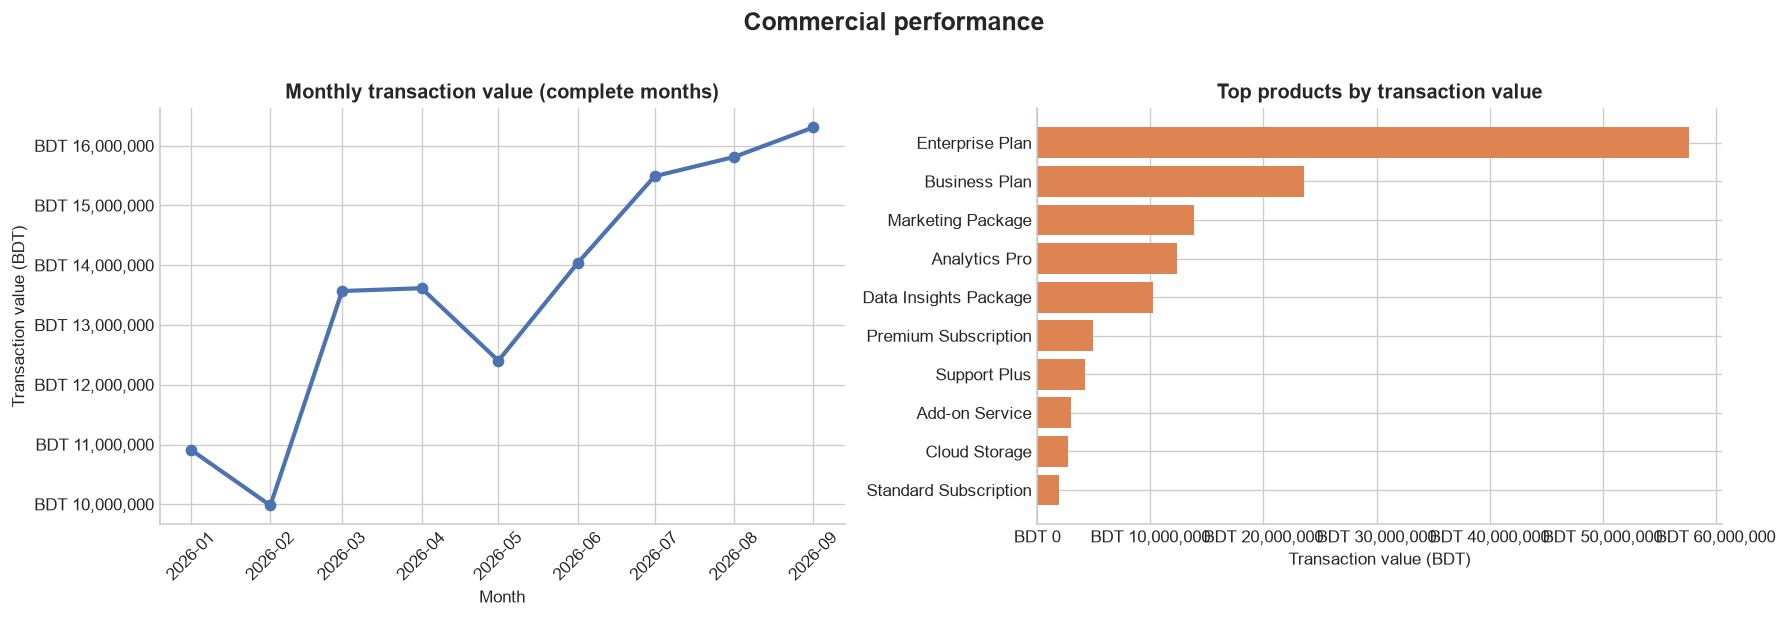

,month,transaction_value,transactions,period_status
0,2026-01-01,10911193.20,776,Complete
1,2026-02-01,9979882.33,737,Complete
2,2026-03-01,13568600.46,908,Complete
3,2026-04-01,13615656.10,943,Complete
4,2026-05-01,12402434.09,951,Complete
5,2026-06-01,14038424.79,1025,Complete
6,2026-07-01,15489672.88,1143,Complete
7,2026-08-01,15811354.17,1141,Complete
8,2026-09-01,16307286.18,1149,Complete
9,2026-10-01,14474454.64,1089,Partial


In [4]:
monthly_value = (
    transactions.assign(month=transactions['transaction_date'].dt.to_period('M').dt.to_timestamp())
    .groupby('month', as_index=False)['amount'].agg(transaction_value='sum', transactions='size')
)
latest_transaction_date = transactions['transaction_date'].max()
latest_month = latest_transaction_date.to_period('M').to_timestamp()
latest_month_is_partial = latest_transaction_date < latest_transaction_date.to_period('M').end_time.normalize()
monthly_value['period_status'] = 'Complete'
if latest_month_is_partial:
    monthly_value.loc[monthly_value['month'].eq(latest_month), 'period_status'] = 'Partial'
complete_monthly_value = monthly_value[monthly_value['period_status'].eq('Complete')]
product_value = (transactions.groupby('product', as_index=False)['amount'].sum().rename(columns={'amount': 'transaction_value'}).sort_values('transaction_value', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(complete_monthly_value['month'], complete_monthly_value['transaction_value'], marker='o', linewidth=2.5, color=COLORS[0])
axes[0].set(title='Monthly transaction value (complete months)', xlabel='Month', ylabel='Transaction value (BDT)')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('BDT {x:,.0f}'))
axes[0].tick_params(axis='x', rotation=45)

top_products = product_value.head(10).sort_values('transaction_value')
axes[1].barh(top_products['product'], top_products['transaction_value'], color=COLORS[1])
axes[1].set(title='Top products by transaction value', xlabel='Transaction value (BDT)')
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter('BDT {x:,.0f}'))
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Commercial performance', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()
monthly_value

## 4. Campaign performance

Campaigns are compared on response volume and response conversion. Transaction value cannot be attributed to campaigns because transactions do not contain a campaign identifier.

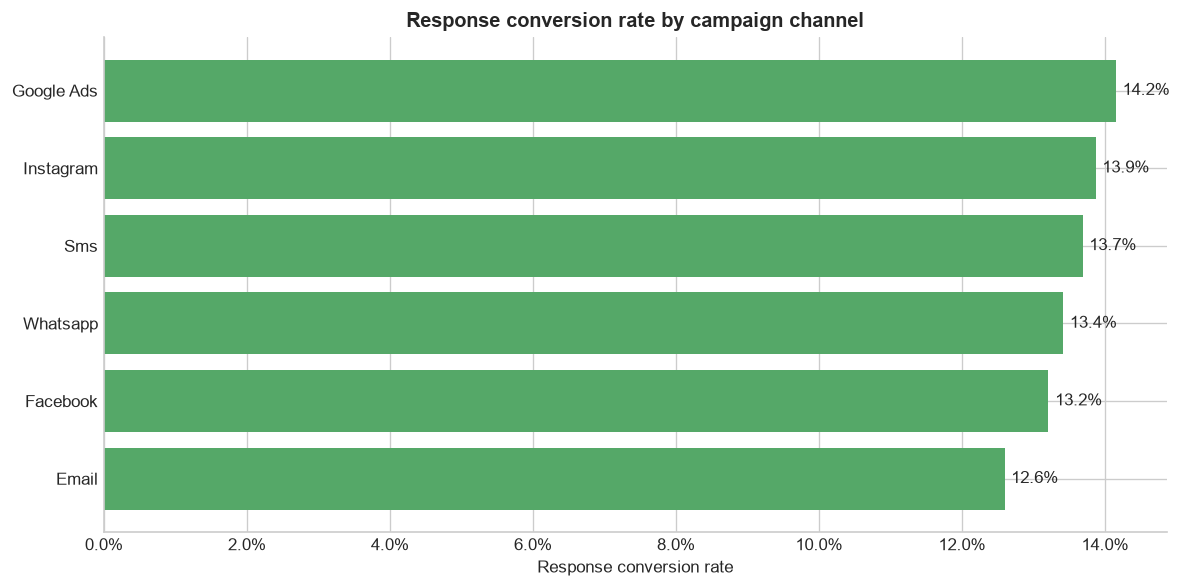

,campaign_name,channel,responses,conversions,conversion_rate,budget,cost_per_response
8,Summer Promotion 09,Sms,77,18,0.233766,25000.0,324.675325
23,Spring Campaign 25,Google Ads,89,18,0.202247,15000.0,168.539326
28,Eid Special 30,Sms,97,19,0.195876,40000.0,412.371134
21,Festival Offer 23,Instagram,189,33,0.174603,25000.0,132.275132
2,Festival Offer 03,Instagram,24,4,0.166667,150000.0,6250.000000
31,Black Friday 33,Email,273,43,0.157509,150000.0,549.450549
7,Festival Offer 08,Whatsapp,301,47,0.156146,15000.0,49.833887
35,Summer Promotion 37,Instagram,291,45,0.154639,150000.0,515.463918
19,Summer Promotion 21,Facebook,240,37,0.154167,50000.0,208.333333
18,Spring Campaign 20,Whatsapp,293,45,0.153584,40000.0,136.518771


In [5]:
campaign_kpis = (
    responses.groupby('campaign_id', as_index=False)
    .agg(responses=('response_id', 'size'), conversions=('converted', 'sum'), conversion_rate=('converted', 'mean'))
    .merge(campaigns[['campaign_id', 'campaign_name', 'channel', 'budget', 'status']], on='campaign_id', how='left')
    .assign(cost_per_response=lambda frame: frame['budget'] / frame['responses'])
    .sort_values(['conversion_rate', 'responses'], ascending=[False, False])
)
channel_kpis = (
    campaign_kpis.groupby('channel', as_index=False)
    .agg(campaigns=('campaign_id', 'nunique'), responses=('responses', 'sum'), conversions=('conversions', 'sum'), budget=('budget', 'sum'))
    .assign(conversion_rate=lambda frame: frame['conversions'] / frame['responses'])
    .sort_values('conversion_rate', ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
channel_plot = channel_kpis.sort_values('conversion_rate')
bars = ax.barh(channel_plot['channel'], channel_plot['conversion_rate'], color=COLORS[2])
ax.bar_label(bars, labels=[f'{value:.1%}' for value in channel_plot['conversion_rate']], padding=4)
ax.set(title='Response conversion rate by campaign channel', xlabel='Response conversion rate')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
campaign_kpis[['campaign_name', 'channel', 'responses', 'conversions', 'conversion_rate', 'budget', 'cost_per_response']].head(10)

## 5. Customer composition and value

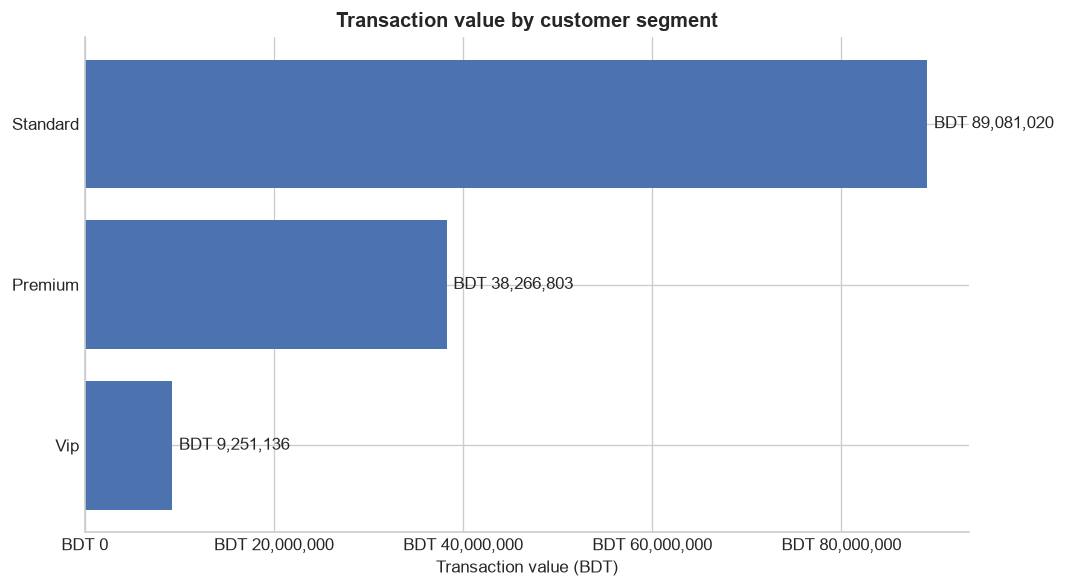

,customer_segment,customers,purchasing_customers,transaction_value,purchaser_rate
1,Standard,3238,2668,89081019.67,0.823965
0,Premium,1414,1149,38266802.81,0.812588
2,Vip,348,293,9251136.36,0.841954


In [6]:
customer_value = (transactions.groupby('customer_id', as_index=False)['amount'].sum().rename(columns={'amount': 'transaction_value'}).merge(customers[['customer_id', 'customer_segment', 'city']], on='customer_id', how='left'))
segment_kpis = (
    customers.groupby('customer_segment', as_index=False).agg(customers=('customer_id', 'nunique'))
    .merge(customer_value.groupby('customer_segment', as_index=False).agg(purchasing_customers=('customer_id', 'nunique'), transaction_value=('transaction_value', 'sum')), on='customer_segment', how='left')
    .fillna({'purchasing_customers': 0, 'transaction_value': 0})
    .assign(purchaser_rate=lambda frame: frame['purchasing_customers'] / frame['customers'])
    .sort_values('transaction_value', ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
segment_plot = segment_kpis.sort_values('transaction_value')
bars = ax.barh(segment_plot['customer_segment'], segment_plot['transaction_value'], color=COLORS[0])
ax.bar_label(bars, labels=[f'BDT {value:,.0f}' for value in segment_plot['transaction_value']], padding=4)
ax.set(title='Transaction value by customer segment', xlabel='Transaction value (BDT)')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('BDT {x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
segment_kpis

## 6. Support operations and customer satisfaction

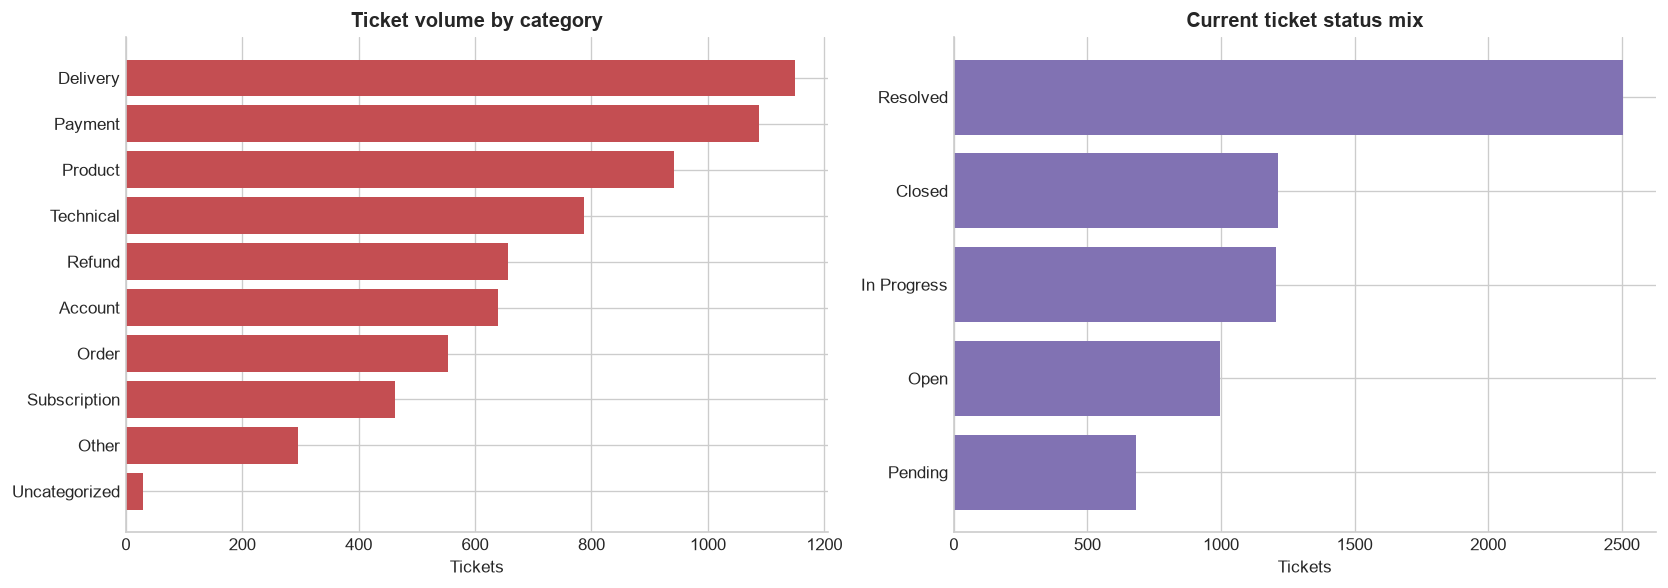

,category,tickets,resolution_rate,average_csat
1,Delivery,1149,0.560487,3.976780
4,Payment,1087,0.558418,3.836634
5,Product,941,0.550478,3.890805
8,Technical,787,0.550191,3.857471
6,Refund,657,0.552511,3.969529
0,Account,639,0.561815,3.882022
2,Order,554,0.575812,3.877743
7,Subscription,462,0.588745,3.878676
3,Other,296,0.554054,3.975758
9,Uncategorized,29,0.724138,3.952381


In [7]:
support_kpis = (
    support_tickets.assign(is_resolved=support_tickets['resolution_date'].notna())
    .groupby('category', as_index=False)
    .agg(tickets=('ticket_id', 'size'), resolution_rate=('is_resolved', 'mean'), average_csat=('satisfaction_score', 'mean'))
    .sort_values('tickets', ascending=False)
)
ticket_status = support_tickets['status'].value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_plot = support_kpis.sort_values('tickets')
axes[0].barh(category_plot['category'], category_plot['tickets'], color=COLORS[3])
axes[0].set(title='Ticket volume by category', xlabel='Tickets')
axes[1].barh(ticket_status.index, ticket_status.values, color=COLORS[4])
axes[1].set(title='Current ticket status mix', xlabel='Tickets')
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
support_kpis

## 7. Findings and caveats

Use the calculated tables above to identify the highest-converting channels, highest-value customer segments, and support categories with the most volume. Key limitations:

- The analysis uses cleaned records only; invalid keys, invalid values, and events that predate the related signup or campaign were excluded upstream.
- The latest transaction month is partial and is shown in the monthly table but excluded from the trend chart.
- Transaction value is not net revenue: refunds cannot be netted without a refund amount or a transaction-refund relationship.
- Campaign-attributed revenue and true marketing ROI cannot be calculated because transactions have no campaign identifier.
- Missing resolution dates represent unresolved or unavailable resolutions; average resolution time excludes these tickets.
- Missing CSAT is not treated as a zero score.